# Lab 11C: Hybrid Recommendation and Validation
**Course 961731 Business Data Analytics, Week 11**

Notebook นี้ทำตามโจทย์ Lab 11C ครบ Part 1.1 ถึง 3.3 โค้ดคำนวณจริงอยู่ใน `lab11C_hybrid_validation.py` ซึ่งใช้ contract ของ Lab 11A และ content/CF ของ Lab 11B

**ภาพรวมแบบง่าย**
1. **Matrix Factorization (MF):** บีบรสนิยมของลูกค้าและ "บุคลิก" ของสินค้าให้เหลือตัวเลขไม่กี่ตัว (factors) แล้วทำนายคะแนนจากการคูณกัน
2. **Hybrid:** ผสม content score กับ MF score แต่ต้องปรับให้อยู่ใน scale เดียวกันก่อน (เหมือนบวกองศากับกิโลเมตรไม่ได้)
3. **Audit:** ตรวจว่าไม่มีอะไรแอบใช้ข้อมูลอนาคต วัดความไม่แน่นอนด้วย bootstrap แล้วออกแบบ A/B test จริง

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..')); sys.path.insert(0, os.path.abspath('../lab11B'))
os.makedirs('figures', exist_ok=True); os.makedirs('evidence', exist_ok=True)
from types import SimpleNamespace
from IPython.display import Image, display
import reco_contract as rc
import lab11B_content_cf as cb
import lab11C_hybrid_validation as lab
df = rc.load_events(); rc.validate_events(df)
train, valid, test = rc.temporal_split(df)
item_vectors, *_ = cb.classroom_tfidf(cb.load_catalog()['Description'])
args = SimpleNamespace(k=rc.K, baseline_rate=0.05, mde_relative=0.10, alpha_level=0.05, power=0.80, daily_users=5000)

## Problem 1: Factor Model

**สูตรทำนาย:** r̂(u,i) = μ + b_u + b_i + p_u · q_i
- **μ** = ค่าเฉลี่ยของทุก rating ใน training
- **b_u** = user bias (ลูกค้าคนนี้ใจดีกว่าปกติแค่ไหน), **b_i** = item bias (สินค้านี้ได้คะแนนดีกว่าปกติแค่ไหน)
- **p_u · q_i** = ความเข้ากันได้ระหว่างรสนิยมลูกค้ากับบุคลิกสินค้า ใน d มิติ

**Regularization (λ):** ลงโทษตัวเลขที่ใหญ่เกินไป เพื่อไม่ให้ model "จำ" ข้อมูล training แทนที่จะ "เรียนรู้" (overfitting) ยิ่งข้อมูลน้อย ยิ่งต้องใช้ λ สูง

**มิติที่ 1 ไม่ใช่หมวดสินค้าเสมอไป:** แกนของ factor หมุนได้โดยที่ผลทำนายไม่เปลี่ยน จึงห้ามตีความว่าเป็น "แกนกาแฟ" เอง

**Fallback:** ลูกค้าหรือสินค้าที่ไม่เคยเห็น ทำนายด้วย μ และห้ามสุ่ม factor ขึ้นมาให้ดูเหมือนเคย train แล้ว


PROBLEM 1.1  SPECIFY THE BIASED FACTOR MODEL
Prediction  r_hat(u,i) = mu + b_u + b_i + p_u . q_i
Objective   J = 0.5 * mean_{(u,i) in E_train} (r_ui - r_hat_ui)^2
              + lambda/2 * (||P||^2 + ||Q||^2 + ||b_user||^2 + ||b_item||^2)
Shapes      P: U x d = 71 x d, Q: I x d = 70 x d, b_user: 71, b_item: 70
Fitted on training only: mu (training global mean), biases, P, Q, ID mappings, chosen (d, lambda).
Optimizer   SGD over training events, 100 epochs, learning rate 0.05, init N(0, 0.1^2), seed 42

PROBLEM 1.2  FIT CANDIDATES, SELECT ON VALIDATION RMSE
Candidates: d in [2, 4, 8], lambda in [0.01, 0.1, 1.0] (9 fits, all kept)
Validation rating population: 17 of 38 events have a known user AND item


 d  lambda  train_objective  val_mae  val_rmse  val_n
 2    0.01           0.7417   1.7861    2.1590     17
 2    0.10           6.3247   1.7440    2.0974     17
 2    1.00          19.2976   1.5296    1.8416     17
 4    0.01           0.7175   1.8160    2.1599     17
 4    0.10           6.2229   1.7762    2.0911     17
 4    1.00          19.3427   1.5310    1.8412     17
 8    0.01           0.6960   1.7568    2.0917     17
 8    0.10           6.0950   1.7246    2.0425     17
 8    1.00          19.4628   1.5323    1.8428     17
Selected d = 4, lambda = 1.0 (lowest validation RMSE; ties -> smaller d, larger lambda)

PROBLEM 1.3  VERIFY STATE, UPDATE AND FALLBACKS
Saved-state reconstruction for (2, 516): manual 3.509981 = predict 3.509981
All 4970 known-pair predictions finite; range 0.759 to 5.109
One-event example: dot = 0.14, prediction = 3.24, residual = 0.76
  b_u 0.2 -> 0.237000; b_i -0.1 -> -0.061500
  p_u [0.2, 0.4] -> [0.218, 0.4018]; q_i [0.5, 0.1] -> [0.5051, 0.1147]
Rat

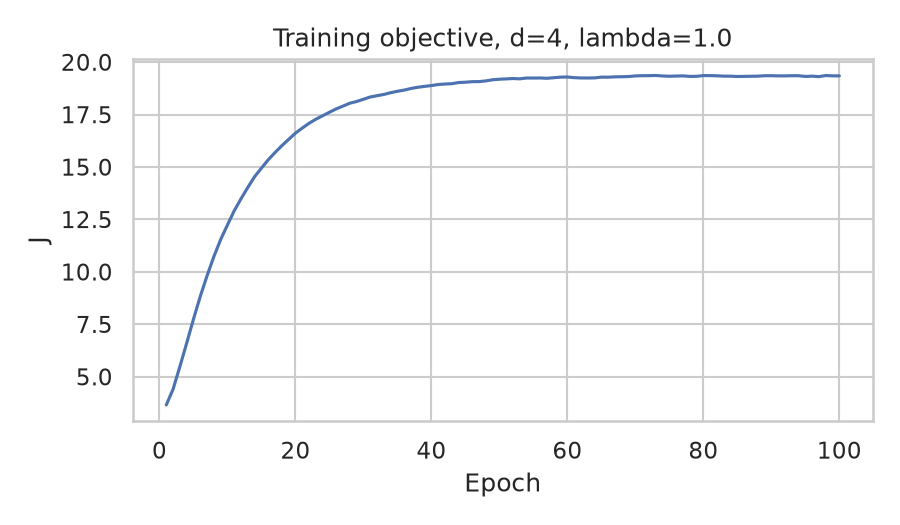

In [2]:
state, users, items, u2i, p2i, record, mf_choice = lab.problem1(train, valid)
display(Image('figures/factor_objective.png'))

## Problem 2: Hybrid

**Min-max scaling:** แปลงคะแนนแต่ละส่วนให้อยู่ระหว่าง 0 ถึง 1 ภายใน request ของลูกค้าคนนั้น แล้วผสมด้วย α x content + (1 - α) x factor

เลือก α จาก grid {0, 0.25, 0.5, 0.75, 1} โดยใช้ **validation** เท่านั้น แล้วจึงเปิด test **ครั้งเดียว** หลังจากล็อกค่าทุกอย่างแล้ว

**MAE/RMSE** ใช้กับ rating ที่ทั้ง user และ item รู้จัก ส่วน **Top-K metrics** ใช้กับ user ที่มี relevant item จำนวนตัวอย่างจึงต่างกันได้


PROBLEM 2.1  CALIBRATE AND BLEND ON VALIDATION
Calibration: per-request min-max of each component over the user's eligible candidates;
a constant component becomes all zeros. Labels are never used in scaling.
Routing: unknown user -> popularity; no positive profile -> content component = 0 (factor drives).
 alpha  val_ndcg@5  val_recall@5  val_coverage
  0.00      0.0431           0.1        0.1429
  0.25      0.0431           0.1        0.2000
  0.50      0.0431           0.1        0.2429
  0.75      0.0431           0.1        0.2429
  1.00      0.0931           0.2        0.2143
Selected alpha = 1.0 (highest validation NDCG@5; ties -> higher coverage, then larger alpha)
Lab reference selected alpha = 0.75 with the companion script; differences come from the factor fit.

One combined score, user 2, item 538: 1.0 x content 1.0000 + 0.0 x factor 0.4591 = 1.0000

PROBLEM 2.2  RANKING TRACE FOR ONE USER
User 2: catalog 70 - seen ['508', '516', '540', '552'] = 66 candidates
     content

[test]
    method  users  precision@5  recall@5  ndcg@5  coverage  diversity  warm_users  warm_ndcg  cold_users  cold_ndcg
popularity      9          0.0       0.0     0.0  0.071429   0.767537           7        0.0           2        0.0
   content      9          0.0       0.0     0.0  0.271429   0.491839           7        0.0           2        0.0
   user_cf      9          0.0       0.0     0.0  0.071429   0.767537           7        0.0           2        0.0
   item_cf      9          0.0       0.0     0.0  0.071429   0.767537           7        0.0           2        0.0
    factor      9          0.0       0.0     0.0  0.157143   0.756420           7        0.0           2        0.0
    hybrid      9          0.0       0.0     0.0  0.271429   0.491839           7        0.0           2        0.0
[validation, for reference]
    method  users  precision@5  recall@5  ndcg@5  coverage  diversity  warm_users  warm_ndcg  cold_users  cold_ndcg
popularity     10         0.04       

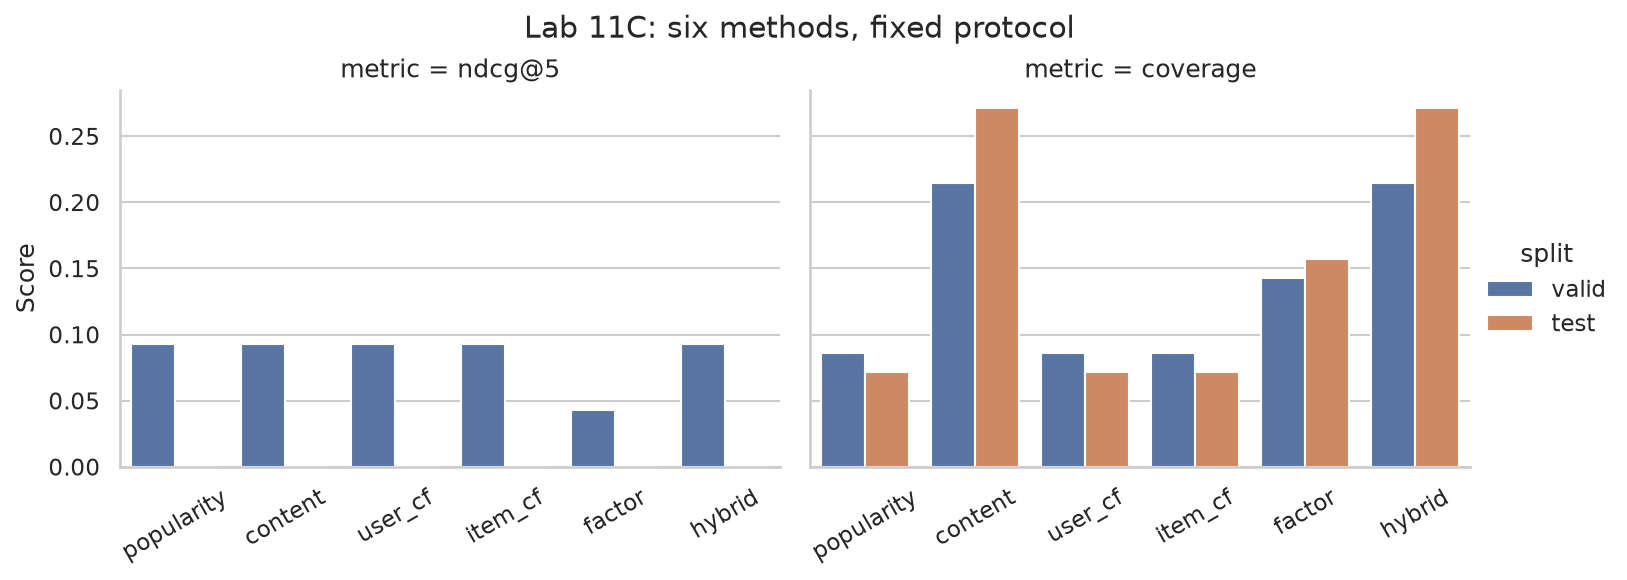

In [3]:
models, alpha, grid, val_table, test_table, errors, per_users = lab.problem2(train, valid, test, item_vectors, state, u2i, p2i, rc.K)
display(Image('figures/six_methods.png'))

## Problem 3: Audit, Uncertainty, A/B Test

**Time audit:** ตรวจว่าทุก object ที่ fit ใช้ข้อมูลก่อน 21 May เท่านั้น และลองทำสำเนาที่ fit บน train + valid เพื่อพิสูจน์ว่า assertion จับได้

**Paired user bootstrap:** สุ่มลูกค้าแบบใส่คืน (ทั้งก้อนต่อคน) แล้วดูช่วงของ "ผลต่าง" ระหว่าง 2 model บนลูกค้าชุดเดียวกัน 9 คนน้อยเกินกว่าที่ช่วงความเชื่อมั่นจะนิ่ง

**A/B test:** สุ่มที่ระดับ user, กำหนด primary outcome หนึ่งตัวและ guardrails, คำนวณ sample size จาก power ก่อนเริ่ม และใช้ fixed stopping rule (ห้ามแอบดูผลกลางทางแล้วหยุด)

In [4]:
audit, boots, resources, design = lab.problem3(df, train, valid, test, models, alpha, mf_choice, record, grid, per_users, args)


PROBLEM 3.1  FITTED-OBJECT TIME AUDIT
                            object fitted_on         latest_event_used  before_boundary
                 popularity counts     train 2024-05-20T18:42:23+00:00             True
                 user/global means     train 2024-05-20T18:42:23+00:00             True
             ID mappings + catalog     train 2024-05-20T18:42:23+00:00             True
          content vocabulary + IDF     train 2024-05-20T18:42:23+00:00             True
                     user profiles     train 2024-05-20T18:42:23+00:00             True
                 CF neighbourhoods     train 2024-05-20T18:42:23+00:00             True
         factors (d=4, lambda=1.0)     train 2024-05-20T18:42:23+00:00             True
hyperparameters (d, lambda, alpha)     valid 2024-06-12T15:54:30+00:00             True
Candidate universe: 70 training items; 20 future-only items excluded
Sampling policy: full ranking over all eligible candidates, no negative sampling.
Deliberate copy fi


Resources: refit chosen factor model + score 32 test users in 0.654 s, peak traced memory 0.04 MiB
Environment: Python 3.13.16, Linux-6.18.44-fc-v139-x86_64-with-glibc2.39, input 121 training events

PROBLEM 3.3  PRE-REGISTERED A/B TEST
unit                        : user (sticky hash of pseudonymous UserID), 50/50
control / treatment         : popularity slot / hybrid slot
primary outcome             : purchase conversion of recommended items per exposed user
guardrails                  : revenue per user, page latency p95, complaint/return rate, catalog coverage
assumed baseline rate       : 5.00% (assumption, replace with logged rate)
minimum detectable effect   : 10% relative -> 5.50%
alpha / power               : 0.05 two-sided / 0.8
users per arm               : 31,231
duration                    : 14 days at 5,000 eligible users/day (whole weeks, >= 2 weekly cycles)
stopping rule               : fixed horizon; analyse once at the planned end, no peeking
